# Attention variants in one tiled kernel: masks, bias, GQA/MQA and block sparsity

*Notebook 5 of 6. Prerequisite: notebook 2 (FA-2 loop). Everything here is a modification of the tile loop, not a new algorithm.*

**TL;DR.** Most "variants" of attention people ask for (causal, sliding window, prefix-LM, packed documents, ALiBi, logit soft-capping, grouped-query attention, block-sparse patterns) differ from standard attention only in two places: the score tile $S_{ij}$ is edited before the softmax (**score modification**), and some tiles may not need to be computed at all (**masking**). We build one tiled forward pass that takes a `score_mod` and a `mask_mod`, classify every tile as empty, partial or full (the idea behind FlexAttention, Dong et al., 2024, [arXiv:2412.05496](https://arxiv.org/abs/2412.05496)), check six masks and two score modifications against a dense float64 reference, and measure what each variant saves or costs. The numbers we measure are tile and FLOP counts and HBM element counts; we do not measure GPU time.

**Contents**
1. Variants as two hooks
2. Masks and tile classification
3. Score modifications: ALiBi and soft-capping
4. Grouped-query and multi-query attention
5. Block-sparse attention
6. What goes wrong: empty rows, tile size, mask cost
7. Summary table
8. Closing thoughts

In [1]:
import math, numpy as np, torch, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import Markdown, display
from fa_kit import *
torch.manual_seed(0); HEAD = {}; print('device:', DEVICE)

device: cpu


## 1. Variants as two hooks

**A tiny example.** Take $N=4$ and a causal mask. The score tile is

$$S=\begin{bmatrix}s_{00}&s_{01}&s_{02}&s_{03}\\ s_{10}&s_{11}&s_{12}&s_{13}\\ s_{20}&s_{21}&s_{22}&s_{23}\\ s_{30}&s_{31}&s_{32}&s_{33}\end{bmatrix}\ \to\ \begin{bmatrix}s_{00}&-\infty&-\infty&-\infty\\ s_{10}&s_{11}&-\infty&-\infty\\ s_{20}&s_{21}&s_{22}&-\infty\\ s_{30}&s_{31}&s_{32}&s_{33}\end{bmatrix}$$

Softmax assigns $e^{-\infty}=0$ weight to the masked entries, so they drop out. Nothing else about the algorithm changes.

**General definition.** Two user functions of the indices $(h,q,kv)$ (head, query position, key position):

* `score_mod(s, h, q, kv)` returns a modified score, e.g. $s-\alpha_h(q-kv)$ for ALiBi.
* `mask_mod(h, q, kv)` returns `True` where attention is allowed.

**How it is implemented.** In the tile loop, after $S_{ij}=Q_iK_j^\top/\sqrt d$ we apply `score_mod`, then fill masked entries with $-\infty$, then continue with the usual online softmax. The efficiency question is the second hook: if a whole tile is masked we should not compute it. Section 2 builds the machinery.

In [2]:
def flash_generic(q, k, v, Br, Bc, mask_mod=None, score_mod=None, block_kind=None, h=0, io=None, fl=None, pos_q=None):
    """FA-2 forward with hooks. block_kind[i][j] in {0: empty (skip), 1: partial (apply mask_mod), 2: full (no mask needed)}.
    pos_q optionally gives the sequence position of each query row (used for GQA packing)."""
    N, d = q.shape; Nk = k.shape[0]; sc = 1 / math.sqrt(d); io = io if io is not None else IOCounter(); fl = fl if fl is not None else FlopCounter()
    pos_q = torch.arange(N) if pos_q is None else pos_q
    O = torch.zeros_like(q); L = torch.full((N,), -float("inf"), dtype=q.dtype)
    for i in range(math.ceil(N / Br)):
        is_ = slice(i * Br, min((i + 1) * Br, N)); Qi = q[is_]; qi = pos_q[is_]; io.read("Q", Qi)
        Ot = torch.zeros_like(Qi); li = torch.zeros(len(Qi), dtype=q.dtype); mi = torch.full((len(Qi),), -float("inf"), dtype=q.dtype)
        for j in range(math.ceil(Nk / Bc)):
            kind = 2 if block_kind is None else int(block_kind[i][j])
            if kind == 0: continue                                                         # EMPTY tile: no loads, no FLOPs
            js = slice(j * Bc, min((j + 1) * Bc, Nk)); Kj, Vj = k[js], v[js]; io.read("K", Kj); io.read("V", Vj); kv = torch.arange(js.start, js.stop)
            S = (Qi @ Kj.T) * sc; fl.mm(len(Qi), len(Kj), d)
            if score_mod is not None: S = score_mod(S, h, qi[:, None], kv[None, :]); fl.elt(S.numel())
            if kind == 1 and mask_mod is not None: S = S.masked_fill(~mask_mod(h, qi[:, None], kv[None, :]), -float("inf")); fl.elt(S.numel())    # PARTIAL: element mask
            mn = torch.maximum(mi, S.max(1).values); ms = torch.where(torch.isinf(mn), torch.zeros_like(mn), mn)
            P = torch.exp(S - ms[:, None]); a = torch.exp(mi - ms); li = a * li + P.sum(1); Ot = a[:, None] * Ot + P @ Vj; fl.mm(len(Qi), d, len(Kj)); mi = mn
        denom = torch.where(li == 0, torch.ones_like(li), li)                              # rows with no allowed key -> output 0, not nan
        O[is_] = Ot / denom[:, None]; L[is_] = torch.where(li == 0, torch.full_like(li, -float("inf")), mi + torch.log(denom)); io.write("O", Ot)
    return O, L

def dense_ref(q, k, v, mask_mod=None, score_mod=None, h=0):
    """float64 dense reference built from the same two hooks."""
    q, k, v = q.double(), k.double(), v.double(); N, Nk = q.shape[0], k.shape[0]; S = q @ k.T / math.sqrt(q.shape[1])
    qi, kv = torch.arange(N)[:, None], torch.arange(Nk)[None, :]
    if score_mod is not None: S = score_mod(S, h, qi, kv)
    if mask_mod is not None: S = S.masked_fill(~mask_mod(h, qi, kv), -float("inf"))
    P = torch.softmax(S, -1); P = torch.nan_to_num(P, nan=0.0); return P @ v

Now the machinery that decides which tiles to skip.

## 2. Masks and tile classification

**A tiny example.** With $N=8$ and $2\times2$ tiles, a causal mask gives 4 diagonal tiles that are *partial* (half masked), $6$ tiles below the diagonal that are *full* (nothing masked, no mask needed), and $6$ above the diagonal that are *empty* (skip entirely).

**General definition.** For a tile of query rows $I$ and key columns $J$: *empty* if $\mathrm{mask}(q,kv)=\text{False}$ for all pairs, *full* if True for all pairs, otherwise *partial*. Only partial tiles pay for element-wise masking; empty tiles cost nothing.

**How it is implemented.** We evaluate the mask on the full grid once (what FlexAttention's `create_block_mask` does at mask-creation time, which has its own cost, discussed in section 6), reduce each tile with `all`/`any`, and store a small integer matrix.

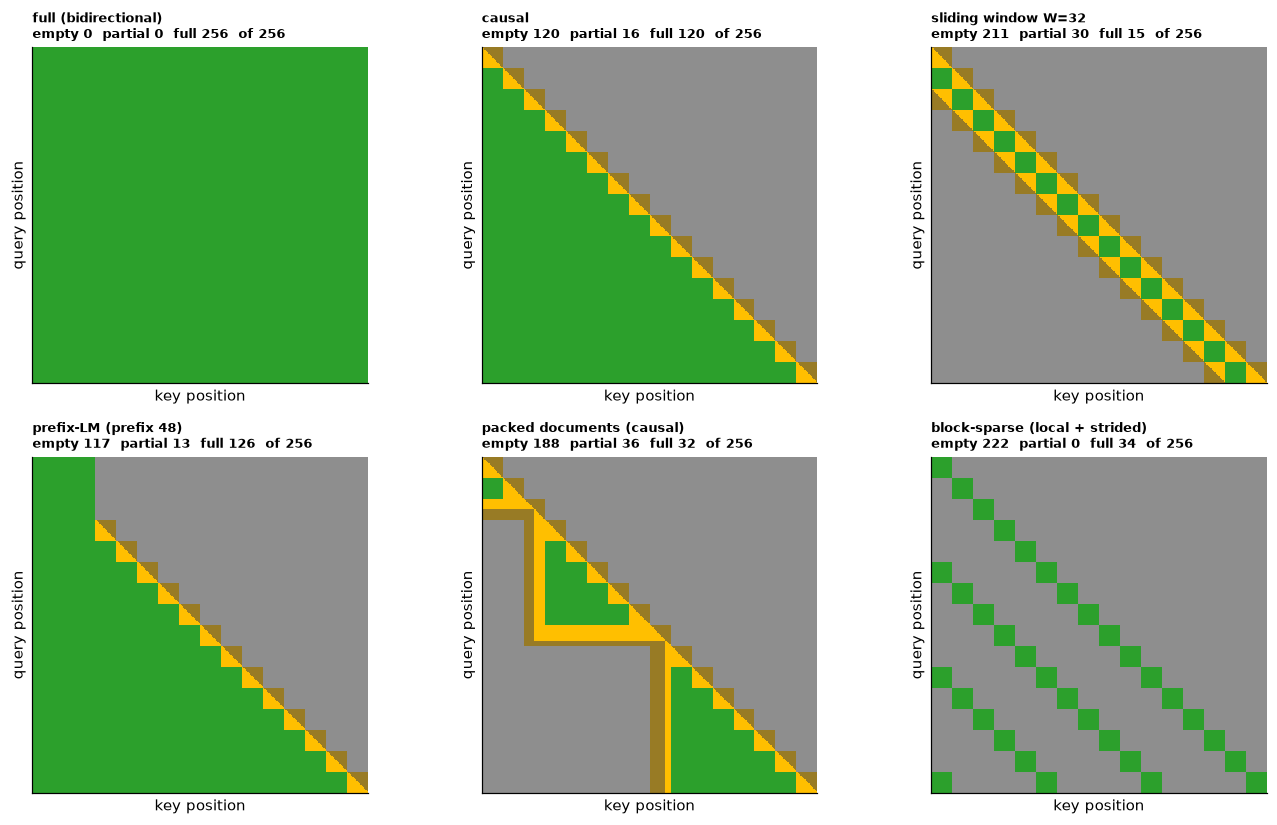

<sub>**Figure.** Green = full tile (compute, no mask), amber = partial tile (compute, apply element mask), grey = empty tile (skipped). The dark overlay marks the individual masked-out entries. Notice that partial tiles sit along the *boundary* of each pattern: the sliding window has a thin band of amber on both sides of the green band, and the packed-documents mask has amber tiles where a document starts in the middle of a tile.</sub>

In [3]:
def block_kinds(mask_mod, N, Br, Bc, h=0):
    """Returns (kind[Tr,Tc] in {0,1,2}, dense mask). kind from all()/any() reductions over each tile."""
    qi, kv = torch.arange(N)[:, None], torch.arange(N)[None, :]; M = mask_mod(h, qi, kv).bool()
    Tr, Tc = N // Br, N // Bc; T = M.reshape(Tr, Br, Tc, Bc)
    full, any_ = T.all(dim=3).all(dim=1), T.any(dim=3).any(dim=1)
    return (any_.long() + full.long()), M
# --- the six masks ---------------------------------------------------------
W_ = 32; PREFIX = 48; DOCS = [40, 100, 116]
doc_id = torch.repeat_interleave(torch.arange(len(DOCS)), torch.tensor(DOCS))               # packed sequences: which document each position belongs to
MASKS = {
    "full (bidirectional)": lambda h, q, kv: (q >= 0) & (kv >= 0),
    "causal":               lambda h, q, kv: q >= kv,
    f"sliding window W={W_}": lambda h, q, kv: (q >= kv) & (q - kv < W_),
    f"prefix-LM (prefix {PREFIX})": lambda h, q, kv: (kv < PREFIX) | (q >= kv),
    "packed documents (causal)": lambda h, q, kv: (q >= kv) & (doc_id[q.clamp(max=255)] == doc_id[kv.clamp(max=255)]),
    "block-sparse (local + strided)": lambda h, q, kv: ((q // 16) == (kv // 16)) | (((q // 16) * 7 + (kv // 16) * 13) % 5 == 0) & (q >= kv),
}
N, Br, Bc = 256, 16, 16; assert sum(DOCS) == N
kinds, dens = {}, {}
fig, axs = plt.subplots(2, 3, figsize=(12.5, 7.6))
cmap = ListedColormap(["#E8E8E8", "#FFBF00", "#2CA02C"])
for ax, (nm, mm) in zip(axs.ravel(), MASKS.items()):
    kd, M = block_kinds(mm, N, Br, Bc); kinds[nm], dens[nm] = kd, M
    ax.imshow(kd.repeat_interleave(Br, 0).repeat_interleave(Bc, 1).cpu().numpy(), cmap=cmap, vmin=0, vmax=2, interpolation="nearest")
    ax.imshow(np.where(M.cpu().numpy(), np.nan, 1.0), cmap=ListedColormap(["#444444"]), alpha=.55, interpolation="nearest")
    cnt = [(kd == t).sum().item() for t in (0, 1, 2)]; ax.set_title(f"{nm}\nempty {cnt[0]}  partial {cnt[1]}  full {cnt[2]}  of {kd.numel()}", fontsize=8.5, loc="left")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel("key position"); ax.set_ylabel("query position")
plt.tight_layout(); plt.show()
caption("Green = full tile (compute, no mask), amber = partial tile (compute, apply element mask), grey = empty tile (skipped). The dark overlay marks the individual masked-out entries. Notice that partial tiles sit along the *boundary* of each pattern: the sliding window has a thin band of amber on both sides of the green band, and the packed-documents mask has amber tiles where a document starts in the middle of a tile.")

In [4]:
# correctness: tiled kernel with block skipping == dense float64 reference, for every mask
rows = []
for nm, mm in MASKS.items():
    q_, k_, v_ = (torch.randn(N, 32, dtype=torch.float64) for _ in range(3)); kd = kinds[nm]
    fl_, io_ = FlopCounter(), IOCounter()
    O_, _ = flash_generic(q_, k_, v_, Br, Bc, mask_mod=mm, block_kind=kd, fl=fl_, io=io_); Or = dense_ref(q_, k_, v_, mask_mod=mm)
    e = max_err(O_, Or); dense_fl = 4 * N * N * 32; kept = (kd > 0).float().mean().item(); elem = dens[nm].float().mean().item()
    analytic = (kd > 0).sum().item() * 4 * Br * Bc * 32
    rows.append((nm, e, kept, elem, fl_.matmul / dense_fl)); check(f"mask '{nm}': tiled == dense reference", e < 1e-11, f"err={e:.1e}")
    check(f"mask '{nm}': counted matmul FLOPs == tiles*4*Br*Bc*d", fl_.matmul == analytic)
print(f"{'mask':<32} {'tiles kept':>10} {'allowed entries':>16} {'FLOPs vs dense':>15}")
for nm, e, kept, elem, fr in rows: print(f"{nm:<32} {kept*100:>9.1f}% {elem*100:>15.1f}% {fr*100:>14.1f}%")
HEAD["masks"] = rows

mask                             tiles kept  allowed entries  FLOPs vs dense
full (bidirectional)                 100.0%           100.0%          100.0%
causal                                53.1%            50.2%           53.1%
sliding window W=32                   17.6%            11.7%           17.6%
prefix-LM (prefix 48)                 54.3%            51.9%           54.3%
packed documents (causal)             26.6%            19.3%           26.6%
block-sparse (local + strided)        13.3%            13.3%           13.3%


Block skipping is exact for all six masks. Two numbers to read from the table: the FLOP fraction (the compute we actually do) and the allowed-entry fraction (the compute an ideal element-level kernel would do). The gap between them is the work spent inside partial tiles on entries that are then masked, and it depends on the tile size, which we examine in section 6.

## 3. Score modifications: ALiBi and soft-capping

**A tiny example.** ALiBi (Press et al., 2022, [arXiv:2108.12409](https://arxiv.org/abs/2108.12409)) replaces positional embeddings by a per-head linear penalty $-\alpha_h(q-kv)$ added to the scores, with slopes $\alpha_h=2^{-8(h+1)/H}$. With $H=8$ the slopes are $\tfrac12,\tfrac14,\dots,\tfrac1{256}$: head 0 looks mostly nearby; head 7 sees almost the whole context.

Soft-capping (used, to our recollection, in Gemma 2; we have not re-checked) bounds logits by $\mathrm{cap}\cdot\tanh(s/\mathrm{cap})$ before the softmax.

**How it is implemented.** Both are element-wise functions of the score and indices, so they slot into the `score_mod` hook. They cost one extra element-wise pass over each tile, which we count. Because they act before the max and exp, they need no change to the online-softmax algebra.

ALiBi slopes: [0.5, 0.25, 0.125, 0.0625, 0.0312, 0.0156, 0.0078, 0.0039]


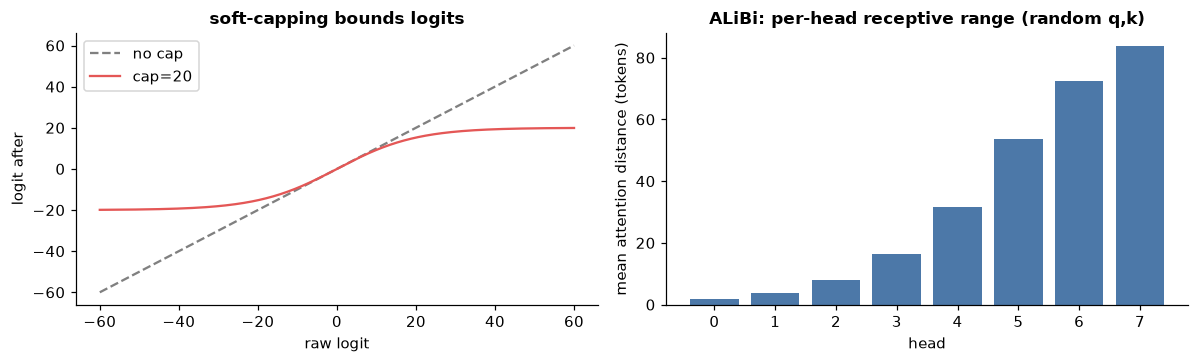

<sub>**Figure.** Left: the cap is linear near zero and saturates at +-20, so very large raw scores can no longer dominate. Right: with random q,k the ALiBi slope alone controls how far back each head looks; slope 1/2 (head 0) attends on average 1.8 tokens back and slope 1/256 (head 7) 84 tokens back in this random-q,k setting. Notice that the distance grows with head index.</sub>

gradient error through soft-cap tiles: 2.220446049250313e-15


True

In [5]:
H_ = 8; slopes = torch.tensor([2.0 ** (-8 * (h + 1) / H_) for h in range(H_)])
alibi = lambda s, h, q, kv: s - slopes[h].to(s.dtype) * (q - kv).to(s.dtype)                         # used with a causal mask
CAP = 20.0; softcap = lambda s, h, q, kv: CAP * torch.tanh(s / CAP)
combo = lambda s, h, q, kv: alibi(softcap(s, h, q, kv), h, q, kv)
print("ALiBi slopes:", [round(x, 4) for x in slopes.tolist()])
causal = MASKS["causal"]; kd_c = kinds["causal"]
for nm, sm in (("ALiBi", alibi), ("soft-cap", softcap), ("soft-cap then ALiBi", combo)):
    for h in (0, 5):
        q_, k_, v_ = (torch.randn(N, 32, dtype=torch.float64) * 3 for _ in range(3))
        O_, _ = flash_generic(q_, k_, v_, Br, Bc, mask_mod=causal, score_mod=sm, block_kind=kd_c, h=h); Or = dense_ref(q_, k_, v_, mask_mod=causal, score_mod=sm, h=h)
        e = max_err(O_, Or); check(f"{nm} (head {h}) + causal: tiled == dense", e < 1e-11, f"err={e:.1e}")
# what each head actually attends to: mean attention distance
q_, k_ = torch.randn(N, 32, dtype=torch.float64), torch.randn(N, 32, dtype=torch.float64); dists = []
for h in range(H_):
    S = q_ @ k_.T / math.sqrt(32); qi, kv = torch.arange(N)[:, None], torch.arange(N)[None, :]; S = alibi(S, h, qi, kv).masked_fill(~causal(h, qi, kv), -float("inf"))
    P = torch.softmax(S, -1); dists.append((P * (qi - kv).clamp(min=0)).sum(1)[N // 2:].mean().item())
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
x = torch.linspace(-60, 60, 400); axs[0].plot(x.cpu(), x.cpu(), "--", color="grey", label="no cap"); axs[0].plot(x.cpu(), (CAP * torch.tanh(x / CAP)).cpu(), color=COL["o"], label=f"cap={CAP:g}"); axs[0].set_xlabel("raw logit"); axs[0].set_ylabel("logit after"); axs[0].legend(); axs[0].set_title("soft-capping bounds logits")
axs[1].bar(range(H_), dists, color=COL["q"]); axs[1].set_xlabel("head"); axs[1].set_ylabel("mean attention distance (tokens)"); axs[1].set_title("ALiBi: per-head receptive range (random q,k)")
plt.tight_layout(); plt.show()
caption("Left: the cap is linear near zero and saturates at +-20, so very large raw scores can no longer dominate. Right: with random q,k the ALiBi slope alone controls how far back each head looks; slope 1/2 (head 0) attends on average 1.8 tokens back and slope 1/256 (head 7) 84 tokens back in this random-q,k setting. Notice that the distance grows with head index.")
check("ALiBi receptive range grows with head index (heads 0 < 7)", dists[0] < dists[-1], f"{dists[0]:.1f} -> {dists[-1]:.1f}")
# autograd through the tiled loops gives the right gradient (softcap has a non-trivial derivative 1 - tanh^2)
q_, k_, v_ = (torch.randn(64, 16, dtype=torch.float64, requires_grad=True) for _ in range(3)); kd64, _ = block_kinds(causal, 64, 16, 16); dO = torch.randn(64, 16, dtype=torch.float64)
O_, _ = flash_generic(q_, k_, v_, 16, 16, mask_mod=causal, score_mod=softcap, block_kind=kd64); (O_ * dO).sum().backward(); g1 = [t.grad.clone() for t in (q_, k_, v_)]
for t in (q_, k_, v_): t.grad = None
(dense_ref(q_, k_, v_, mask_mod=causal, score_mod=softcap) * dO).sum().backward(); g2 = [t.grad for t in (q_, k_, v_)]
e = max(max_err(a, b) for a, b in zip(g1, g2)); print("gradient error through soft-cap tiles:", e); check("gradients through score_mod tiles match dense autograd", e < 1e-11)

Both modifications are exact, and the gradient passes through `score_mod` correctly. A hand-written backward kernel would need to multiply $dS$ by the derivative of the modification (here $1-\tanh^2(s/\mathrm{cap})$); that is the part a compiler such as FlexAttention derives automatically, and the part we did not write by hand here.

## 4. Grouped-query and multi-query attention

**A tiny example.** A model has $H=4$ query heads. In multi-head attention (MHA) each has its own K and V head. In **multi-query attention** (MQA, Shazeer, 2019, [arXiv:1911.02150](https://arxiv.org/abs/1911.02150)) all 4 share one K/V head; in **grouped-query attention** (GQA, Ainslie et al., 2023, [arXiv:2305.13245](https://arxiv.org/abs/2305.13245)) they are split into groups, e.g. 2 groups of 2. Query head $h$ uses KV head $\lfloor h/G\rfloor$, $G=H/H_{kv}$.

**General definition.** The attention math is identical per query head; only the *K/V storage* shrinks by $G$. The KV cache per token per layer is $2\,H_{kv}\,d$ elements.

In [6]:
Hq, d, Nk = 8, 32, 192
def gqa_reference(q, k, v, causal=True):                       # q:(Hq,Nq,d) k,v:(Hkv,N,d): expand K/V then standard attention
    G = q.shape[0] // k.shape[0]; ke, ve = k.repeat_interleave(G, 0), v.repeat_interleave(G, 0)
    return torch.stack([ref_attention(q[h], ke[h], ve[h], causal=causal)[0] for h in range(q.shape[0])])
for Hkv in (8, 4, 2, 1):                                        # MHA, GQA-2, GQA-4, MQA
    q = torch.randn(Hq, Nk, d, dtype=torch.float64); k, v = (torch.randn(Hkv, Nk, d, dtype=torch.float64) for _ in range(2)); G = Hq // Hkv
    kd, _ = block_kinds(causal, Nk, 16, 16)
    out = torch.stack([flash_generic(q[h], k[h // G], v[h // G], 16, 16, mask_mod=causal, block_kind=kd, h=h)[0] for h in range(Hq)])
    e = max_err(out, gqa_reference(q, k, v)); check(f"GQA Hq=8 Hkv={Hkv} (G={G}): tiled == expanded-KV reference", e < 1e-11, f"err={e:.1e}")

Mathematically that is all. The performance consequence shows up in two places. First, **KV-cache size**, computed exactly below. Second, **decode arithmetic intensity**: in decoding every query head reads the same K/V chunk for its group. If the kernel processes the $G$ query heads of a group *together* (stacking them as $G$ rows of a single query block), the K/V chunk is read **once** for $G$ heads instead of $G$ times. We implement that packing and count the loads.

config           KV elems read (unpacked)   (packed)  ratio  err
Hq=8 Hkv=8                          1048576    1048576    1.0  2e-16
Hq=8 Hkv=4                          1048576     524288    2.0  2e-16
Hq=8 Hkv=2                          1048576     262144    4.0  2e-16
Hq=8 Hkv=1                          1048576     131072    8.0  2e-16


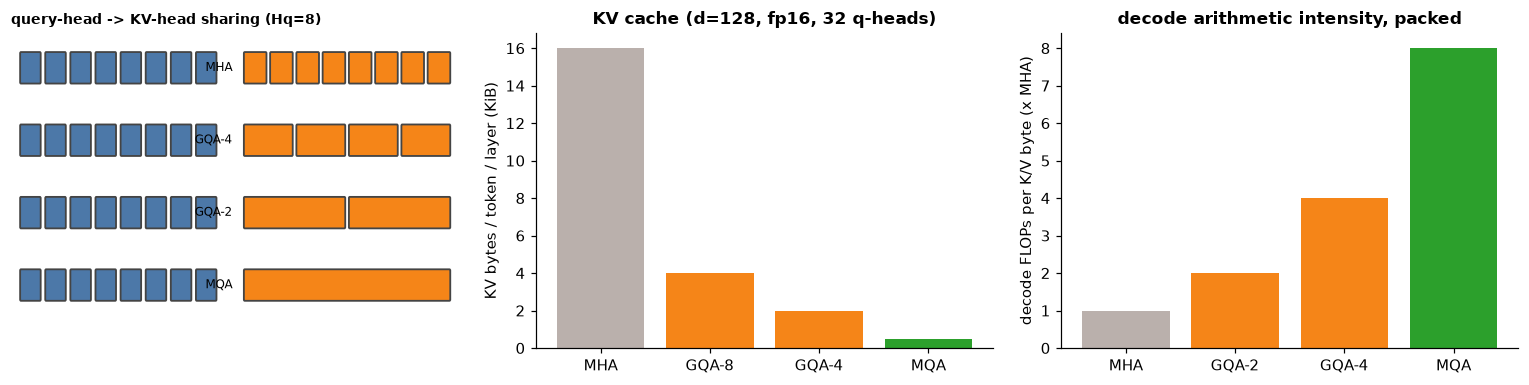

<sub>**Figure.** Left: blue = query heads, orange = KV heads; sharing shrinks the orange row. Middle: KV storage falls in proportion to the number of KV heads (16 KiB to 0.5 KiB per token per layer at fp16 for our example shape). Right: when the group's query heads are packed into one block, each K/V element read is reused G times, so decode FLOPs per byte rise by G. Notice that this second benefit exists only in decoding: in prefill each head already has many query rows to amortise the K/V read.</sub>

In [7]:
def gqa_decode_io(Hq, Hkv, Nk, d, Bc, pack):
    """Run the tile loop over real tensors and count K/V HBM reads for a single decode step (Nq=1)."""
    G = Hq // Hkv; q = torch.randn(Hq, 1, d, dtype=torch.float64); k, v = (torch.randn(Hkv, Nk, d, dtype=torch.float64) for _ in range(2)); io = IOCounter(); outs = torch.zeros(Hq, 1, d, dtype=torch.float64)
    for hk in range(Hkv):
        if pack:   # one Q block of G rows: K/V tiles are loaded once per KV head
            qp = q[hk * G:(hk + 1) * G, 0]; O_, _ = flash_generic(qp, k[hk], v[hk], max(G, 1), Bc, io=io, pos_q=torch.full((G,), Nk - 1)); outs[hk * G:(hk + 1) * G, 0] = O_
        else:      # one Q block per query head: K/V tiles are loaded G times
            for g in range(G): O_, _ = flash_generic(q[hk * G + g], k[hk], v[hk], 1, Bc, io=io, pos_q=torch.full((1,), Nk - 1)); outs[hk * G + g] = O_
    ref = gqa_reference(q, k, v, causal=False); return io.reads["K"] + io.reads["V"], max_err(outs, ref)
print(f"{'config':<14} {'KV elems read (unpacked)':>26} {'(packed)':>10} {'ratio':>6}  err")
res = []
for Hkv in (8, 4, 2, 1):
    a, ea = gqa_decode_io(8, Hkv, 1024, 64, 128, pack=False); b, eb = gqa_decode_io(8, Hkv, 1024, 64, 128, pack=True); res.append((Hkv, a, b))
    print(f"Hq=8 Hkv={Hkv:<3}     {a:>26} {b:>10} {a/b:>6.1f}  {max(ea, eb):.0e}"); check(f"packed GQA decode exact, Hkv={Hkv}", max(ea, eb) < 1e-11)
check("packing reads exactly Hq/Hkv times fewer K/V elements", all(a == b * (8 // h) for h, a, b in res))
# KV cache size per token, per layer, fp16: MHA vs GQA vs MQA for a 32-head, d=128 model (shape chosen for illustration)
cfg = {"MHA (32 kv heads)": 32, "GQA (8 kv heads)": 8, "GQA (4 kv heads)": 4, "MQA (1 kv head)": 1}; kv_bytes = {k_: 2 * h * 128 * 2 for k_, h in cfg.items()}
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
ax = axs[0]; ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 5); ax.set_title("query-head -> KV-head sharing (Hq=8)", loc="left", fontsize=9)
for i, (nm, hk) in enumerate((("MHA", 8), ("GQA-4", 4), ("GQA-2", 2), ("MQA", 1))):
    y = 4.2 - i * 1.15
    for h in range(8): box(ax, .2 + h * .55, y, .45, .5, "", COL["q"], round_=.02)
    for g in range(hk): w = 8 * .55 / hk; box(ax, 5.1 + g * (4.6 / hk), y, 4.6 / hk - .08, .5, "", COL["k"], round_=.02)
    ax.text(4.85, y + .25, nm, ha="right", fontsize=8, va="center")
axs[1].bar(range(4), [v_ / 1024 for v_ in kv_bytes.values()], color=[COL["hbm"], COL["k"], COL["k"], COL["good"]]); axs[1].set_xticks(range(4)); axs[1].set_xticklabels(["MHA", "GQA-8", "GQA-4", "MQA"]); axs[1].set_ylabel("KV bytes / token / layer (KiB)"); axs[1].set_title("KV cache (d=128, fp16, 32 q-heads)")
axs[2].bar(range(4), [8 // h for h, _, _ in res], color=[COL["hbm"], COL["k"], COL["k"], COL["good"]]); axs[2].set_xticks(range(4)); axs[2].set_xticklabels(["MHA", "GQA-2", "GQA-4", "MQA"]); axs[2].set_ylabel("decode FLOPs per K/V byte (x MHA)"); axs[2].set_title("decode arithmetic intensity, packed")
plt.tight_layout(); plt.show()
caption("Left: blue = query heads, orange = KV heads; sharing shrinks the orange row. Middle: KV storage falls in proportion to the number of KV heads (16 KiB to 0.5 KiB per token per layer at fp16 for our example shape). Right: when the group's query heads are packed into one block, each K/V element read is reused G times, so decode FLOPs per byte rise by G. Notice that this second benefit exists only in decoding: in prefill each head already has many query rows to amortise the K/V read.")
HEAD["gqa"] = (kv_bytes, res)

The costs are on the model-quality side, not the kernel side: sharing K/V across heads reduces representational capacity, which the GQA paper *reports* can be recovered by short up-training; we did not train anything here, so we cannot say how much quality is lost in any setting. In our notebook the cost shows up as nothing: the numerics are exact, the cache is smaller and decode reuses each K/V byte $G$ times.

## 5. Block-sparse attention

**A tiny example.** A $16\times16$ grid of tiles where only a fraction $s$ of tiles are non-empty. FlashAttention (the 2022 paper) shows that skipping empty tiles reduces both FLOPs and HBM traffic roughly in proportion to $s$.

**How it is implemented.** It is exactly the `block_kind` skip from section 2, with a pattern chosen for modelling reasons rather than from a formula, such as local blocks plus global blocks plus strided blocks. We vary the density, count real loop traffic, and compare against $s\times$ the dense count.

tile density s | FLOPs / dense | HBM traffic / dense
          0.15 |          0.15 |     0.20
          0.21 |          0.21 |     0.26
          0.30 |          0.30 |     0.34
          0.49 |          0.49 |     0.52
          0.71 |          0.71 |     0.72
          1.00 |          1.00 |     1.00


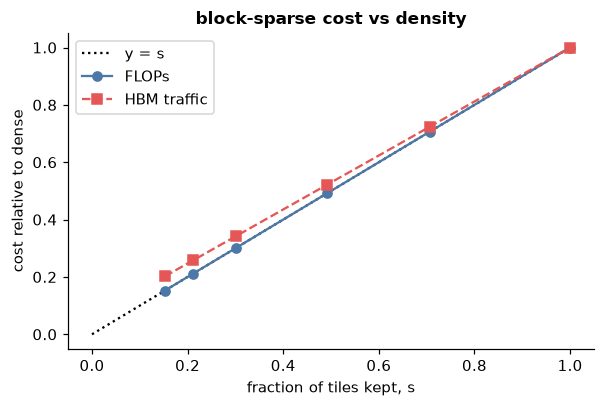

<sub>**Figure.** FLOPs fall exactly along y=s (the blue markers sit on the dotted line). HBM traffic sits above it because Q, O and the K/V tiles that are still needed are not reduced by sparsity in the same proportion: each Q block is read once regardless of how few K/V tiles it visits. Notice that the gap shrinks as density rises and that at s=1 both curves meet at 1.</sub>

In [8]:
N, Bsz, d = 512, 32, 32; Tn = N // Bsz; g = torch.Generator(device=DEVICE).manual_seed(1)
def sparse_pattern(density):
    """Always keep the diagonal (so every row has an allowed key) and block 0 (a 'global' column); add random off-diagonal blocks to hit the density."""
    keep = torch.eye(Tn, dtype=torch.bool); keep[:, 0] = True
    extra = (torch.rand(Tn, Tn, generator=g) < density); return keep | extra
q_, k_, v_ = (torch.randn(N, d, dtype=torch.float64) for _ in range(3))
pts = []
for dens_ in (0.05, 0.1, 0.2, 0.4, 0.7, 1.0):
    keep = sparse_pattern(dens_); kd = keep.long() * 2; mm = lambda h, q, kv, keep=keep: keep[q // Bsz, kv // Bsz]                  # block-granular mask: all tiles are "full"
    io_, fl_ = IOCounter(), FlopCounter(); O_, _ = flash_generic(q_, k_, v_, Bsz, Bsz, mask_mod=mm, block_kind=kd, io=io_, fl=fl_)
    e = max_err(O_, dense_ref(q_, k_, v_, mask_mod=mm)); s = keep.float().mean().item(); dio = IOCounter(); flash_generic(q_, k_, v_, Bsz, Bsz, io=dio)
    pts.append((s, fl_.matmul / (4 * N * N * d), io_.total / dio.total, e)); check(f"block-sparse density~{dens_}: tiled == dense", e < 1e-11, f"actual density {s:.2f}")
print(f"{'tile density s':>14} | FLOPs / dense | HBM traffic / dense")
for s, f, i_, _ in pts: print(f"{s:>14.2f} | {f:>13.2f} | {i_:>8.2f}")
fig, ax = plt.subplots(figsize=(5.6, 3.8)); xs = [p[0] for p in pts]; ax.plot([0, 1], [0, 1], "k:", label="y = s"); ax.plot(xs, [p[1] for p in pts], "o-", color=COL["q"], label="FLOPs"); ax.plot(xs, [p[2] for p in pts], "s--", color=COL["o"], label="HBM traffic")
ax.set_xlabel("fraction of tiles kept, s"); ax.set_ylabel("cost relative to dense"); ax.legend(); ax.set_title("block-sparse cost vs density")
plt.tight_layout(); plt.show()
caption("FLOPs fall exactly along y=s (the blue markers sit on the dotted line). HBM traffic sits above it because Q, O and the K/V tiles that are still needed are not reduced by sparsity in the same proportion: each Q block is read once regardless of how few K/V tiles it visits. Notice that the gap shrinks as density rises and that at s=1 both curves meet at 1.")
check("FLOPs scale exactly with tile density", all(abs(p[1] - p[0]) < 1e-9 for p in pts))
check("HBM traffic is >= s*dense traffic (Q/O fixed cost)", all(p[2] >= p[0] - 1e-9 for p in pts))
HEAD["bs"] = pts

FLOPs follow density exactly, and traffic follows it from above. What a pattern costs in model quality is outside what a kernel can tell you.

## 6. What goes wrong: empty rows, tile size, mask cost

**Empty rows.** If a query has *no* allowed keys (possible with sliding windows combined with other masks, or padding), then every score is $-\infty$, $m=-\infty$, and `exp(S - m)` is `nan`. We reproduce it, then show which behaviour our guard implements (zero output, $L=-\infty$). PyTorch's reference softmax would also return `nan` here, so the choice of convention is the kernel's to make.

In [9]:
hole = lambda h, q, kv: (q >= kv) & ~((q >= 40) & (q < 48))                                         # rows 40..47 may attend to nothing
q_, k_, v_ = (torch.randn(64, 16, dtype=torch.float64) for _ in range(3)); kd, M = block_kinds(hole, 64, 16, 16)
S = (q_ @ k_.T / 4).masked_fill(~M, -float("inf")); naive = torch.softmax(S, -1) @ v_
O_, L_ = flash_generic(q_, k_, v_, 16, 16, mask_mod=hole, block_kind=kd)
print("rows with no allowed key:", (~M.any(1)).sum().item(), "| naive softmax has nan:", torch.isnan(naive).any().item(), "| guarded kernel has nan:", torch.isnan(O_).any().item())
print("guarded output for an empty row:", O_[41, :4].tolist(), " L =", L_[41].item())
check("empty rows give nan in the unguarded softmax", torch.isnan(naive).any().item()); check("guarded kernel returns 0 (no nan) for empty rows", (not torch.isnan(O_).any()) and O_[40:48].abs().max() == 0)
check("non-empty rows are still exact", max_err(O_[~(~M.any(1))], torch.nan_to_num(naive)[~(~M.any(1))]) < 1e-11)

rows with no allowed key: 8 | naive softmax has nan: True | guarded kernel has nan: False
guarded output for an empty row: [0.0, 0.0, 0.0, 0.0]  L = -inf


True

**Tile size.** Large tiles use hardware well but waste work at pattern boundaries: a tile that straddles the edge of a sliding window is *partial* and is computed in full. We measure the fraction of FLOPs spent versus the ideal element-level count for a window of 256 over a 4096 context.

ideal (element-level) fraction = 6.06%   dense causal would be 50.0%
 tile | tiles computed | waste vs ideal | partial tiles
   16 |          6.43% |         1.06x |     0.76%
   32 |          6.81% |         1.12x |     1.51%
   64 |          7.57% |         1.25x |     3.03%
  128 |          9.08% |         1.50x |     6.05%
  256 |         12.11% |         2.00x |    12.11%
  512 |         23.44% |         3.87x |    23.44%


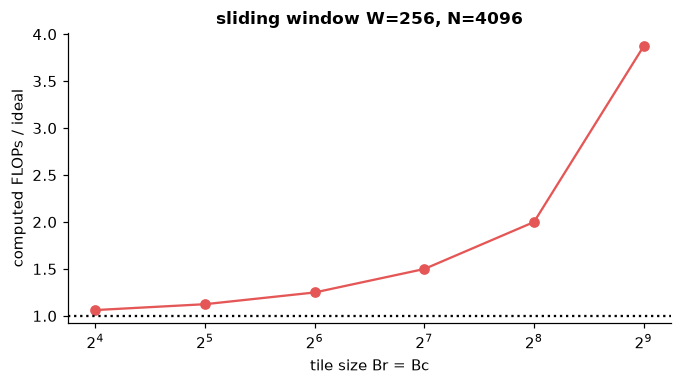

<sub>**Figure.** Small tiles follow the window closely (ratio near 1); at 256 the computed work is 2.0x the ideal (3.9x at 512) because every tile touching the diagonal band is computed whole. Notice that this is exactly opposite to what the hardware wants (bigger tiles reuse data better), so tile size for sparse patterns is a trade-off rather than a free parameter.</sub>

In [10]:
N = 4096; W = 256; mm = lambda h, q, kv: (q >= kv) & (q - kv < W)
qi, kv = torch.arange(N)[:, None], torch.arange(N)[None, :]; Mfull = mm(0, qi, kv); ideal = Mfull.float().mean().item()
res = []
for B in (16, 32, 64, 128, 256, 512):
    T = Mfull.reshape(N // B, B, N // B, B); anyt, allt = T.any(3).any(1), T.all(3).all(1)
    kept = anyt.float().mean().item(); partial = (anyt & ~allt).float().mean().item(); res.append((B, kept, partial))
print(f"ideal (element-level) fraction = {ideal*100:.2f}%   dense causal would be {(0.5+0.5/N)*100:.1f}%")
print(f"{'tile':>5} | tiles computed | waste vs ideal | partial tiles")
for B, kept, part in res: print(f"{B:>5} | {kept*100:>13.2f}% | {kept/ideal:>12.2f}x | {part*100:>8.2f}%")
fig, ax = plt.subplots(figsize=(6.3, 3.6)); ax.plot([r[0] for r in res], [r[1] / ideal for r in res], "o-", color=COL["o"]); ax.axhline(1, color="k", ls=":")
ax.set_xscale("log", base=2); ax.set_xlabel("tile size Br = Bc"); ax.set_ylabel("computed FLOPs / ideal"); ax.set_title(f"sliding window W={W}, N={N}")
plt.tight_layout(); plt.show()
caption("Small tiles follow the window closely (ratio near 1); at 256 the computed work is 2.0x the ideal (3.9x at 512) because every tile touching the diagonal band is computed whole. Notice that this is exactly opposite to what the hardware wants (bigger tiles reuse data better), so tile size for sparse patterns is a trade-off rather than a free parameter.")
check("larger tiles never compute fewer FLOPs than smaller ones for this pattern", all(res[i][1] <= res[i + 1][1] + 1e-12 for i in range(len(res) - 1)))
HEAD["tile"] = res

**Mask cost.** Computing `block_kinds` evaluates the mask on all $N^2$ pairs. For a dense $N=4096$ mask that is 16.8 M booleans, which we can afford once for a static pattern but not per step if the pattern changes every call (for example, per-batch packed-document boundaries). That cost is what motivates the compile-time block-mask structures in FlexAttention, which we have not reproduced. We measure it directly.

In [11]:
import time
for N_ in (1024, 4096, 8192):
    sync(); t0 = time.perf_counter(); kd_, _ = block_kinds(MASKS["causal"], N_, 64, 64); sync(); dt = time.perf_counter() - t0
    print(f"N={N_:>5}: building block kinds took {dt*1e3:8.1f} ms on {DEVICE}, mask has {N_*N_/1e6:6.1f} M entries ({N_*N_/1e6:.0f} MB as bool)")
print("(single-run timings on this device, for scale only; not a benchmark)")

N= 1024: building block kinds took      1.2 ms on cpu, mask has    1.0 M entries (1 MB as bool)
N= 4096: building block kinds took      7.2 ms on cpu, mask has   16.8 M entries (17 MB as bool)
N= 8192: building block kinds took     23.8 ms on cpu, mask has   67.1 M entries (67 MB as bool)
(single-run timings on this device, for scale only; not a benchmark)


## 7. Summary table

| variant | where it enters the kernel | exact (checked) | cost (measured here) |
|---|---|---|---|
| causal | `mask_mod`; empty tiles skipped | yes | FLOPs ~ 53% of dense at 16x16 tiles (see table in section 2) |
| sliding window | `mask_mod` | yes | 2.0x ideal FLOPs at tile 256, 1.06x at tile 16 (section 6) |
| prefix-LM / packed documents | `mask_mod` | yes | FLOPs per section 2 table |
| ALiBi / soft-cap | `score_mod` | yes, forward and gradient | one extra element-wise pass per tile |
| GQA / MQA | head indexing; pack group rows for decode | yes | KV cache 4-32x smaller in our example; K/V reads per decode step divided by G |
| block-sparse | `block_kind` | yes | FLOPs = s x dense; traffic above s x dense |
| empty rows | needs guard | yes, with guard | nan without it |

In [12]:
rows = HEAD["masks"]; pts = HEAD["bs"]; kvb, gres = HEAD["gqa"]
display(Markdown("**Measured FLOP fraction of dense (256 tokens, 16x16 tiles):** " + "; ".join(f"{nm} {fr*100:.0f}%" for nm, _, _, _, fr in rows) + f".  **GQA decode K/V reads, Hq=8:** " + ", ".join(f"Hkv={h}: {a/b:.0f}x fewer when packed" for h, a, b in gres) + "."))

**Measured FLOP fraction of dense (256 tokens, 16x16 tiles):** full (bidirectional) 100%; causal 53%; sliding window W=32 18%; prefix-LM (prefix 48) 54%; packed documents (causal) 27%; block-sparse (local + strided) 13%.  **GQA decode K/V reads, Hq=8:** Hkv=8: 1x fewer when packed, Hkv=4: 2x fewer when packed, Hkv=2: 4x fewer when packed, Hkv=1: 8x fewer when packed.

## 8. Closing thoughts

Nothing in this notebook changes the online-softmax algebra. Masks decide which tiles exist; score modifications edit tiles before the softmax; GQA changes how heads index K/V; each is a small, checkable edit to the loop from notebook 2. The practical lesson is the one the tile-size experiment shows: sparsity pays only to the extent the tile granularity can follow it.

**What is open.** We verified forward exactness for every variant and gradient exactness for soft-capping through autograd, but we did not write a hand-derived flash backward for score modifications, and our block-mask construction is dense $O(N^2)$ at creation time. We cite FlexAttention, ALiBi, MQA and GQA from the papers but did not reproduce their reported model-quality or speed results; our statements on speed are limited to FLOP and traffic counts. Sliding-window plus packed-documents plus ALiBi in one kernel, for example, is a combination we have not benchmarked.

**Next.** Notebook 6 takes the associative merge from notebooks 1 and 4 across devices: Ring Attention.

Checks run in this notebook:

In [13]:
report()

PASS mask 'full (bidirectional)': tiled == dense reference   [err=5.6e-16]
PASS mask 'full (bidirectional)': counted matmul FLOPs == tiles*4*Br*Bc*d
PASS mask 'causal': tiled == dense reference   [err=8.9e-16]
PASS mask 'causal': counted matmul FLOPs == tiles*4*Br*Bc*d
PASS mask 'sliding window W=32': tiled == dense reference   [err=6.7e-16]
PASS mask 'sliding window W=32': counted matmul FLOPs == tiles*4*Br*Bc*d
PASS mask 'prefix-LM (prefix 48)': tiled == dense reference   [err=6.7e-16]
PASS mask 'prefix-LM (prefix 48)': counted matmul FLOPs == tiles*4*Br*Bc*d
PASS mask 'packed documents (causal)': tiled == dense reference   [err=4.7e-16]
PASS mask 'packed documents (causal)': counted matmul FLOPs == tiles*4*Br*Bc*d
PASS mask 'block-sparse (local + strided)': tiled == dense reference   [err=6.7e-16]
PASS mask 'block-sparse (local + strided)': counted matmul FLOPs == tiles*4*Br*Bc*d
PASS ALiBi (head 0) + causal: tiled == dense   [err=9.3e-15]
PASS ALiBi (head 5) + causal: tiled == dens